# 04 - Modèles : baseline, régression linéaire, gradient boosting

**But** : mesurer ce que les features du notebook 03 permettent de prédire, et surtout **comprendre** où et pourquoi
le modèle se trompe.

## Choix et justifications

| choix | décision | pourquoi |
|---|---|---|
| données | les **1M lignes** | les modèles sont rapides (20 s / 1 min) ; plus de données = estimations plus stables, surtout pour les Elo rares (< 1000, > 2400) |
| split | **80 / 20 par joueur** (`GroupShuffleSplit`) | un même joueur a un Elo quasi constant et un style reconnaissable : s'il est dans le train et le test, le score est trop optimiste (notebook 01) |
| validation croisée | **non** | avec ~200k lignes de test, la MAE est estimée à ±1 point près : un seul split suffit pour comparer des modèles |
| prétraitement | dans un **`Pipeline`** sklearn | imputation, standardisation et encodage apprennent leurs paramètres **sur le train seulement** → pas de fuite vers le test |
| modèles | médiane → **régression linéaire** → **HistGradientBoosting** | du plus simple (référence) au plus flexible. Le linéaire est lisible ; le boosting gère les relations en U et les interactions (pendule × cadence) |
| Random Forest | **non** | même famille que le boosting (arbres), mais lente et gourmande en mémoire sur 1M lignes, et en général moins bonne |
| PCA | **non** | 24 features, ce n'est pas beaucoup ; la PCA ignore l'Elo (elle garde la variance, pas l'information utile) et rend le modèle illisible. Utile plus tard pour les n-grammes |
| métriques | **MAE** (principale), RMSE, R², MAE par tranche d'Elo | MAE = erreur moyenne en points d'Elo ; R² = part de variance expliquée ; par tranche = voir la régression vers la moyenne |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import polars as pl

from elo import modeles  # le code du pipeline : chargement, split, pipelines, scores (src/elo/modeles.py)

pl.Config.set_tbl_rows(30)
plt.rcParams["figure.dpi"] = 110

## 1. Données

Deux petites préparations :
- les booléens (`petit_roque`, `dame_precoce`…) deviennent 0/1 ;
- `fin = inconnu` (1,5 %) est un **artefact du nettoyage** (l'adversaire a été filtré, cf. notebook 03) : le modèle
  ne doit pas pouvoir le repérer. On sait que la partie est perdue, ni au temps ni nulle : c'est un mat reçu ou un
  abandon. On met `a_abandonne`, le cas le plus fréquent des deux (2 fois plus que `mat_recu`).

In [2]:
feats = modeles.charge()
CAT, NUM = modeles.CAT, modeles.colonnes_num(feats)
print(f"{feats.height} lignes, {len(NUM)} numériques, {len(CAT)} catégorielles")

1023985 lignes, 24 numériques, 5 catégorielles


## 2. Split train / test par joueur

`GroupShuffleSplit` tire 20 % des **joueurs** (pas des lignes) pour le test : toutes les parties d'un joueur sont du
même côté.

In [3]:
train, test = modeles.split(feats)

X_train, y_train = train.select(CAT + NUM), train["elo"].to_numpy()
X_test, y_test = test.select(CAT + NUM), test["elo"].to_numpy()

print(f"train : {train.height} lignes, {train['joueur'].n_unique()} joueurs")
print(f"test  : {test.height} lignes, {test['joueur'].n_unique()} joueurs")
print("joueurs communs :", len(set(train["joueur"]) & set(test["joueur"])))
pl.DataFrame({"train": train["elo"].describe()["value"], "test": test["elo"].describe()["value"]}).insert_column(
    0, train["elo"].describe()["statistic"]
)

train : 819155 lignes, 119491 joueurs
test  : 204830 lignes, 29873 joueurs


joueurs communs : 0


statistic,train,test
str,f64,f64
"""count""",819155.0,204830.0
"""null_count""",0.0,0.0
"""mean""",1689.544747,1687.938256
"""std""",349.91606,352.488313
"""min""",400.0,400.0
"""25%""",1455.0,1453.0
"""50%""",1709.0,1706.0
"""75%""",1931.0,1931.0
"""max""",2985.0,2937.0


Aucun joueur commun, et les deux distributions d'Elo sont quasi identiques : le test est représentatif.

## 3. Baseline : toujours prédire la médiane du train

In [4]:
resultats, preds = [], {}


def evalue(nom, pred):
    preds[nom] = pred
    resultats.append({"modele": nom, **modeles.scores(y_test, pred)})
    return pl.DataFrame(resultats)


evalue("mediane", np.full(len(y_test), np.median(y_train)))

modele,MAE,RMSE,R2
str,f64,f64,f64
"""mediane""",282.9,353.1,-0.004


## 4. Régression linéaire

Pipeline :
- **numériques** : valeurs manquantes remplacées par la médiane **+ une colonne indicatrice** « était manquant »
  (l'absence de `t_finale` ou de `coup_du_roque` est une information), puis standardisation (moyenne 0, écart-type 1)
  pour que les coefficients soient comparables ;
- **catégorielles** : one-hot, les catégories de moins de 1 % regroupées dans « infrequent ».

⚠️ **Colinéarité** : `pct_pions` + `pct_cavalier` + `pct_fou` + `pct_tour` + `pct_dame` + `pct_roi` ≈ 100 % (chaque coup
est joué par une pièce, à part les roques). Une de ces colonnes se déduit des autres : la régression linéaire ne peut
alors pas répartir l'effet entre elles et donne des coefficients énormes et arbitraires (on l'a vu en testant : toutes
autour de +100). On retire donc `pct_pions` **pour le linéaire seulement** : elle devient la référence, et le
coefficient de `pct_dame` se lit « jouer la dame plutôt qu'un pion ». (Le boosting n'a pas ce problème.)

In [5]:
lineaire = modeles.lineaire(NUM)  # retire pct_pions (colinéarité), voir src/elo/modeles.py
print(lineaire)
lineaire.fit(X_train, y_train)
evalue("lineaire", lineaire.predict(X_test))

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['n_coups', 't_ouverture',
                                                   't_milieu', 't_finale',
                                                   'pct_rapides', 'pct_longs',
                                                   't_max', 'coup_t_max',
                                                   'cv_temps', 'pct_zeitnot',
                                                   'temps_rest

modele,MAE,RMSE,R2
str,f64,f64,f64
"""mediane""",282.9,353.1,-0.004
"""lineaire""",249.4,311.2,0.221


**Les coefficients** : combien de points d'Elo quand la feature augmente d'un écart-type (numériques), ou quand on
est dans cette catégorie (one-hot, par rapport à la moyenne des autres).

In [6]:
coefs = pl.DataFrame({
    "feature": lineaire[0].get_feature_names_out(),
    "coef": lineaire[-1].coef_,
}).sort(pl.col("coef").abs(), descending=True)
coefs.head(20)

feature,coef
str,f64
"""cat__eco_lettre_E""",120.906772
"""cat__premier_coup_Nf3""",110.723974
"""cat__premier_coup_b6""",-109.493749
"""cat__premier_coup_c4""",102.538978
"""cat__premier_coup_Nf6""",93.499446
"""cat__fin_adv_abandonne""",88.047256
"""cat__premier_coup_g6""",-82.712274
"""num__temps_restant_fin""",-74.573097
"""cat__premier_coup_e5""",-72.054521



- Les plus gros effets viennent de l'**ouverture** : `eco_lettre_E` (+121), `Nf3` (+111), `c4` (+103), `Nf6` (+93)
  tirent vers le haut ; `b6` (-109), `g6` (-83), `e5` (-72), `d5` (-56) vers le bas. Cohérent avec le notebook 03.
- Puis la **fin de partie** : faire abandonner l'adversaire (+88) plutôt que perdre au temps (-57) ou se faire mater (-50).
- Côté **pendule** : `pct_rapides` (+61), `t_ouverture` (-52), `cv_temps` (+44), `temps_restant_fin` (-75).

⚠️ Un coefficient se lit « **à autres features égales** ». Comme beaucoup de features sont liées entre elles
(notebook 03, section 5), un coefficient isolé peut surprendre : par exemple `temps_restant_fin` est négatif alors
que ce n'est pas « finir avec peu de temps » qui rend fort. Les coefficients décrivent le modèle, pas une cause.


## 5. HistGradientBoosting

Des centaines de petits arbres de décision, chacun corrigeant les erreurs des précédents. Différences avec le linéaire :
- capte les relations **en U** et les **interactions** (ex. : la même `t_ouverture` n'a pas le même sens en 180+0 et en 180+2) ;
- gère les **valeurs manquantes** tout seul (pas d'imputation) et n'a pas besoin de standardisation ;
- catégorielles : simplement numérotées (`OrdinalEncoder`) et déclarées comme catégorielles.

`max_iter=500` arbres au maximum, avec **arrêt précoce** : sklearn garde 10 % du train pour la validation et s'arrête
quand le score ne s'améliore plus (évite le sur-apprentissage).

In [7]:
boosting = modeles.boosting(NUM)
print(boosting)
boosting.fit(X_train, y_train)
print("arbres utilisés :", boosting[-1].n_iter_)
evalue("boosting", boosting.predict(X_test))

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('cat',
                                                  OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                 min_frequency=0.01,
                                                                 unknown_value=-1),
                                                  ['couleur', 'cadence', 'fin',
                                                   'premier_coup',
                                                   'eco_lettre']),
                                                 ('num', 'passthrough',
                                                  ['n_coups', 't_ouverture',
                                                   't_milieu', 't_finale',
                                                   'pct_rapides', 'pct_longs',
                                                   't_max', 'coup_t_max',
                                            

arbres utilisés : 474


modele,MAE,RMSE,R2
str,f64,f64,f64
"""mediane""",282.9,353.1,-0.004
"""lineaire""",249.4,311.2,0.221
"""boosting""",240.7,300.9,0.271



| modèle | MAE | gain vs médiane | R² |
|---|---|---|---|
| médiane | 283 | — | 0 |
| linéaire | 249 | -34 | 0,22 |
| boosting | 241 | -42 | 0,27 |

- Le linéaire fait déjà l'essentiel du travail ; le boosting gagne 8 points de plus grâce aux relations en U et aux
  interactions.
- Le boosting a utilisé 474 arbres sur 500 : l'arrêt précoce ne s'est presque pas déclenché, on pourrait en autoriser
  plus, mais le gain serait faible.
- **R² = 0,27** : le modèle explique environ un quart de la variance de l'Elo. C'est modeste mais cohérent avec le
  notebook 03 (aucune feature au-dessus de |ρ| = 0,27) : sur une seule partie, le signal est faible.


## 6. Où le modèle se trompe-t-il ? Erreur selon l'Elo

À gauche : Elo **prédit** moyen pour chaque tranche d'Elo **réel** (la diagonale = prédiction parfaite).
À droite : MAE par tranche.

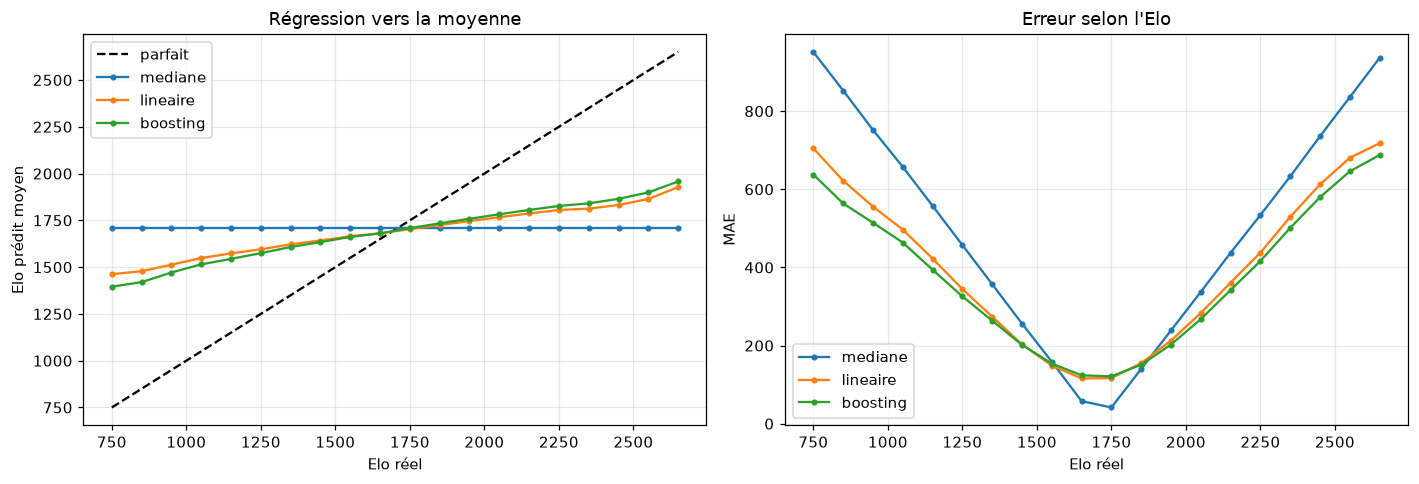

In [8]:
res = test.select("joueur", "elo", "n_coups").with_columns(**{nom: pl.Series(p) for nom, p in preds.items()})
MODELES = list(preds)

par_tranche = (
    res.with_columns(tranche=pl.col("elo") // 100 * 100)
    .group_by("tranche")
    .agg(
        n=pl.len(),
        *[pl.col(m).mean().alias(f"pred_{m}") for m in MODELES],
        *[(pl.col(m) - pl.col("elo")).abs().mean().alias(f"mae_{m}") for m in MODELES],
    )
    .filter(pl.col("n") >= 300)
    .sort("tranche")
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
centre = par_tranche["tranche"] + 50
ax1.plot(centre, centre, "k--", label="parfait")
for m in MODELES:
    ax1.plot(centre, par_tranche[f"pred_{m}"], marker=".", label=m)
    ax2.plot(centre, par_tranche[f"mae_{m}"], marker=".", label=m)
ax1.set(xlabel="Elo réel", ylabel="Elo prédit moyen", title="Régression vers la moyenne")
ax2.set(xlabel="Elo réel", ylabel="MAE", title="Erreur selon l'Elo")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()


**Forte régression vers la moyenne** : un joueur à 750 est prédit ~1400 en moyenne, un joueur à 2650 ~1950.
Quand le signal est faible, prédire près du centre est ce qui minimise l'erreur moyenne : le modèle « n'ose pas »
les valeurs extrêmes.

Conséquence : la MAE est ~120 au centre (1600-1800, là où sont la plupart des joueurs) mais 600-700 aux extrêmes.
**La MAE globale de 241 cache cette disparité** : c'est pour ça qu'on regarde toujours l'erreur par tranche.
Le boosting est un peu moins « écrasé » que le linéaire, mais le problème reste le même : il manque de l'information
pour reconnaître un très bon ou un très mauvais joueur.


## 7. Quelles features comptent vraiment ? Importance par permutation

Pour chaque feature, on **mélange** ses valeurs dans le test (on casse son lien avec l'Elo) et on regarde de combien
la MAE augmente. Grosse hausse = le modèle s'appuie beaucoup dessus. Contrairement à la corrélation du notebook 03,
on mesure l'apport **en présence des autres features**. Calculé sur 50k lignes du test, 3 répétitions.

In [9]:
importances = modeles.importance_permutation(boosting, X_test, y_test).sort("hausse_MAE")
fig = px.bar(importances, x="hausse_MAE", y="feature", orientation="h", height=700,
             title="Hausse de la MAE quand on mélange la feature (boosting)")
fig.show()
importances.sort("hausse_MAE", descending=True)

feature,hausse_MAE
str,f64
"""cv_temps""",11.371464
"""pct_rapides""",10.347806
"""t_ouverture""",7.660185
"""premier_coup""",7.24994
"""temps_restant_fin""",6.777757
"""fin""",6.032631
"""pct_captures""",5.909114
"""pct_roi""",3.919081
"""eco_lettre""",3.50544



- La **pendule domine** : `cv_temps` (+11 points de MAE si on la mélange), `pct_rapides` (+10), `t_ouverture` (+8),
  `temps_restant_fin` (+7). Puis `premier_coup`, `fin` et `pct_captures` (~6-7).
- **Corrélation ≠ apport** : `petit_roque` (ρ = 0,12 au notebook 03) ou `coup_t_max` (ρ = 0,16) ne servent presque
  plus à rien ici. Leur information est déjà portée par d'autres features (redondance).
- Une quinzaine de features ont une importance < 1 point (`pct_tour`, `pct_dame`, `t_milieu`, `t_finale`, roques,
  `couleur`…) : on pourrait probablement les retirer sans perte, pour un modèle plus simple.
- La `cadence` pèse peu (1,4) : malgré le décalage de la pendule vu au notebook 03, le modèle en a peu besoin.


## 8. Erreur selon la longueur de la partie

Plus la partie est longue, plus on a de coups pour juger le joueur. C'est aussi une façon de vérifier le seuil
« au moins 10 coups par joueur » du notebook 01.

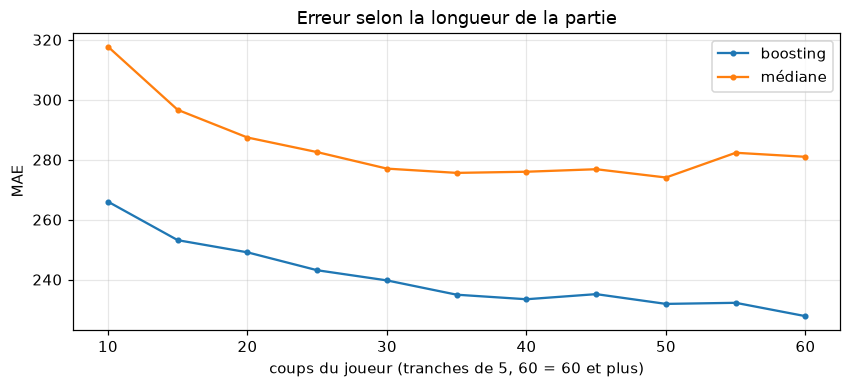

n_coups,n,mae_boosting,mae_mediane
u32,u32,f64,f64
10,10230,266.004101,317.708016
15,17981,253.152171,296.629665
20,25027,249.091816,287.398849
25,29855,243.11933,282.526578
30,28487,239.727781,277.023204
35,23923,234.959065,275.599214
40,18895,233.442711,275.982429
45,14909,235.147651,276.820779
50,11315,231.892363,274.056739


In [10]:
par_longueur = (
    res.with_columns(n_coups=pl.col("n_coups").clip(upper_bound=60) // 5 * 5)
    .group_by("n_coups")
    .agg(n=pl.len(), mae_boosting=(pl.col("boosting") - pl.col("elo")).abs().mean(),
         mae_mediane=(pl.col("mediane") - pl.col("elo")).abs().mean())
    .sort("n_coups")
)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(par_longueur["n_coups"], par_longueur["mae_boosting"], marker=".", label="boosting")
ax.plot(par_longueur["n_coups"], par_longueur["mae_mediane"], marker=".", label="médiane")
ax.set(xlabel="coups du joueur (tranches de 5, 60 = 60 et plus)", ylabel="MAE", title="Erreur selon la longueur de la partie")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
par_longueur


- L'erreur baisse avec la longueur de la partie : 266 (10-14 coups) → 228 (60 coups et plus). Plus de coups =
  plus d'information sur le joueur.
- Mais la baseline est aussi plus mauvaise sur les parties courtes (elles concernent des joueurs plus extrêmes).
  Le **gain par rapport à la médiane** reste de 40 à 50 points quelle que soit la longueur, même pour 10-14 coups.

→ Les parties courtes apportent bien de l'information : le seuil de 10 coups par joueur (notebook 01) ne retire rien
d'utile, il n'y a pas de raison de le monter.


## 9. Et avec plusieurs parties du même joueur ?

Une seule partie est très bruitée (on peut bien ou mal jouer ce jour-là). Si on fait la **moyenne des prédictions**
sur k parties d'un même joueur, l'erreur devrait baisser. On prend les joueurs du test ayant au moins 20 parties,
on mélange leurs parties, et on compare la moyenne des k premières prédictions à leur Elo.

joueurs utilisés : 2068


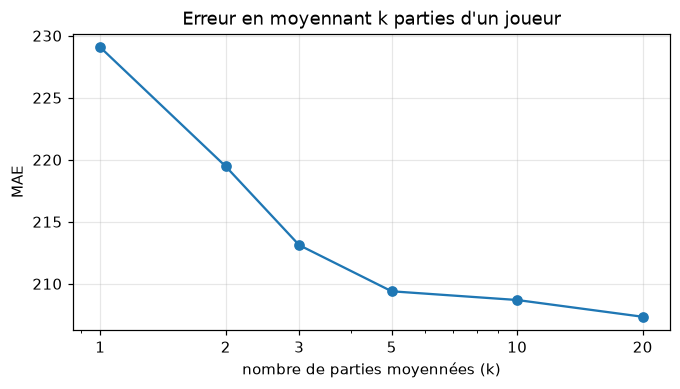

k,MAE
i64,f64
1,229.06895
2,219.461728
3,213.118967
5,209.394945
10,208.692044
20,207.340369


In [11]:
K = [1, 2, 3, 5, 10, 20]
multi = (
    res.sample(fraction=1, shuffle=True, seed=0)
    .with_columns(rang=pl.int_range(pl.len()).over("joueur"), n_parties=pl.len().over("joueur"))
    .filter(pl.col("n_parties") >= 20)
)
print("joueurs utilisés :", multi["joueur"].n_unique())

par_k = pl.DataFrame([
    {
        "k": k,
        "MAE": multi.filter(pl.col("rang") < k)
        .group_by("joueur")
        .agg(pred=pl.col("boosting").mean(), elo=pl.col("elo").mean())
        .select((pl.col("pred") - pl.col("elo")).abs().mean())
        .item(),
    }
    for k in K
])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(par_k["k"], par_k["MAE"], marker="o")
ax.set(xscale="log", xticks=K, xticklabels=K, xlabel="nombre de parties moyennées (k)", ylabel="MAE",
       title="Erreur en moyennant k parties d'un joueur")
ax.grid(alpha=0.3)
plt.show()
par_k


- Moyenner les prédictions fait baisser l'erreur de 229 (1 partie) à 209 (5 parties), puis **plus rien** (207 à 20 parties).
- Moyenner enlève le **bruit** d'une partie à l'autre (bien ou mal jouer ce jour-là). Ce qui reste (~207) est un
  **biais** : pour un joueur donné, le modèle se trompe toujours dans le même sens (la régression vers la moyenne de la
  section 6).

→ Le problème n'est donc pas d'avoir trop peu de parties, mais des **features pas assez informatives**. Il faut
mesurer la **qualité** des coups, pas seulement leur forme.

(Ces 2068 joueurs ont au moins 20 parties dans la journée : ce sont des joueurs plutôt « centraux », d'où une MAE à
1 partie (229) plus basse que la MAE globale (241).)



## Bilan

| modèle | MAE | R² |
|---|---|---|
| médiane | 283 | 0 |
| régression linéaire | 249 | 0,22 |
| HistGradientBoosting | **241** | **0,27** |

**Ce qu'on a appris**
- Les features « de forme » (pendule, types de coups, ouverture, fin) expliquent ~un quart de la variance de l'Elo.
  La **pendule** est la famille la plus utile (`cv_temps`, `pct_rapides`, `t_ouverture`).
- Le modèle **écrase les prédictions vers 1700** : bon au centre (MAE ~120), mauvais aux extrêmes (600-700).
- Ce n'est pas un manque de parties (moyenner 20 parties plafonne à ~207) mais un **manque de signal**.
- Pièges rencontrés : colinéarité des `pct_*` dans le linéaire ; une feature corrélée à l'Elo peut n'apporter rien
  une fois les autres présentes.

**Prochaines étapes**, de la plus simple à la plus coûteuse :
1. **Simplifier** : retirer les features d'importance < 1 et vérifier que la MAE ne bouge pas.
2. **Features d'échiquier** (python-chess) : matériel perdu, pièces laissées en prise, menaces… = la qualité des coups.
3. **N-grammes de coups** (TF-IDF) : les séquences typiques de chaque niveau.
4. **Évaluations** (`%eval`, 9 % des parties) : perte d'évaluation moyenne par coup = mesure directe de la qualité,
   probablement le meilleur signal possible, mais sur un sous-ensemble biaisé (notebook 01).
